In [ ]:
!!pip install datashader

['Collecting datashader',
 '  Downloading datashader-0.19.1-py3-none-any.whl.metadata (8.0 kB)',
 'Requirement already satisfied: colorcet in /usr/local/lib/python3.13/dist-packages (from datashader) (3.2.1)',
 'Requirement already satisfied: multipledispatch in /usr/local/lib/python3.13/dist-packages (from datashader) (1.0.0)',
 'Requirement already satisfied: numba in /usr/local/lib/python3.13/dist-packages (from datashader) (0.61.2)',
 'Requirement already satisfied: numpy in /usr/local/lib/python3.13/dist-packages (from datashader) (2.1.3)',
 'Requirement already satisfied: packaging in /usr/local/lib/python3.13/dist-packages (from datashader) (26.3)',
 'Requirement already satisfied: pandas in /usr/local/lib/python3.13/dist-packages (from datashader) (2.2.3)',
 'Requirement already satisfied: param in /usr/local/lib/python3.13/dist-packages (from datashader) (2.4.2)',
 'Collecting pyct (from datashader)',
 '  Downloading pyct-0.6.0-py3-none-any.whl.metadata (7.2 kB)',
 'Requiremen

In [ ]:
import io
import pandas as pd
from google.colab import files
import matplotlib.pyplot as plt
import datashader as ds
import datashader.transfer_functions as tf


In [ ]:
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=",")
print(f"Файл '{file_name}' успішно завантажено!")

# Первинний аналіз
print("Розмір датасету:", df.shape)
print("\nТипи даних:\n", df.dtypes)
print("\nКількість пропущених значень:\n", df.isnull().sum())
print("\nСтатистичні характеристики числових змінних:\n", df.describe())

Saving ЛБ1-Зведений-датасет.csv to ЛБ1-Зведений-датасет (1).csv
Файл 'ЛБ1-Зведений-датасет (1).csv' успішно завантажено!
Розмір датасету: (16598, 17)

Типи даних:
 Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
Critic_Score    float64
Critic_Count    float64
User_Score       object
User_Count      float64
Developer        object
Rating           object
dtype: object

Кількість пропущених значень:
 Rank               0
Name               0
Platform           0
Year             271
Genre              0
Publisher         58
NA_Sales           0
EU_Sales           0
JP_Sales           0
Other_Sales        0
Global_Sales       0
Critic_Score    8280
Critic_Count    8280
User_Score      6652
User_Count      8777
Developer       6585
Rating          6714
dtype: int64

Статистичні

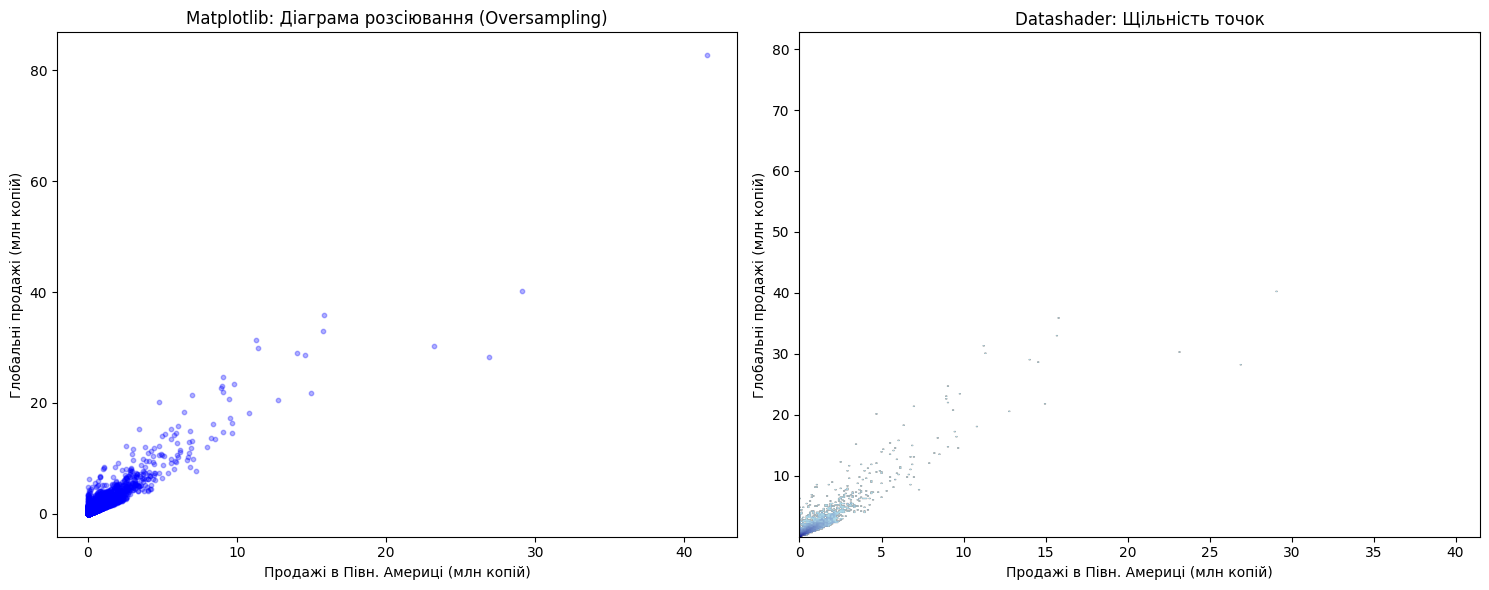

In [28]:
data = df[["NA_Sales", "Global_Sales"]].dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- 1.Matplotlib ---
axes[0].scatter(data["NA_Sales"], data["Global_Sales"], alpha=0.3, s=10, color='blue')
axes[0].set_title("Matplotlib: Діаграма розсіювання (Oversampling)")
axes[0].set_xlabel("Продажі в Півн. Америці (млн копій)")
axes[0].set_ylabel("Глобальні продажі (млн копій)")

# --- 2. Datashader ---
canvas = ds.Canvas(plot_width=400, plot_height=400)
agg = canvas.points(data, "NA_Sales", "Global_Sales", agg=ds.count())
img = tf.shade(agg, cmap=["lightblue", "darkblue"], how="log")

# Відображення результату Datashader у Matplotlib
img_pil = img.to_pil()
axes[1].imshow(img_pil, aspect='auto',
               extent=[data["NA_Sales"].min(), data["NA_Sales"].max(),
                       data["Global_Sales"].min(), data["Global_Sales"].max()])
axes[1].set_title("Datashader: Щільність точок")
axes[1].set_xlabel("Продажі в Півн. Америці (млн копій)")
axes[1].set_ylabel("Глобальні продажі (млн копій)")

plt.tight_layout()
plt.show()

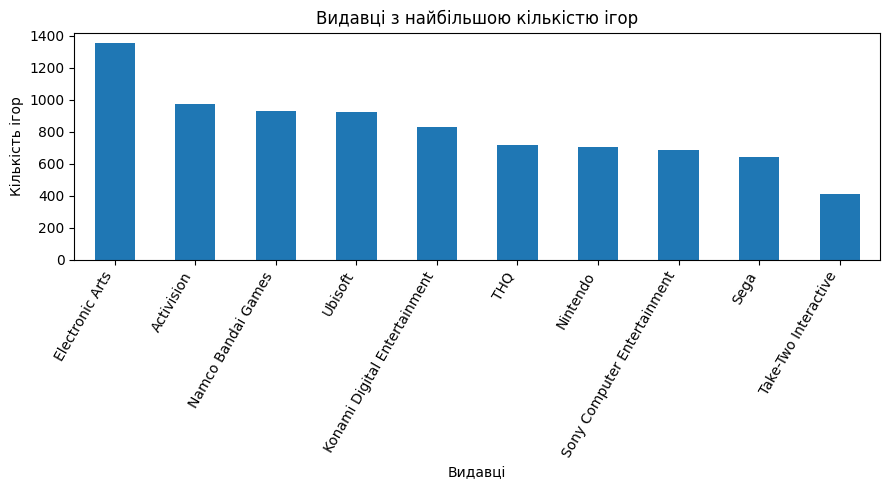

In [ ]:
Publisher = df["Publisher"].value_counts().head(10)
plt.figure(figsize=(9, 5))
Publisher.plot(kind="bar")
plt.title("Видавці з найбільшою кількістю ігор")
plt.xlabel("Видавці")
plt.ylabel("Кількість ігор")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()